# B2 — Transfer by heuristic: sentiment model + rule "negative ⇒ sarcastic"

`CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment`, no training. Two variants per preprocessing:
`hard` (argmax = negative, fixed 0.5) and `soft` (P(negative), threshold tuned on val).

**Contamination warning**: this model was fine-tuned on ASTD / ArSAS / SemEval, and ArSarcasm v1 (inside ArSarcasm-v2) re-annotated
ASTD and SemEval-2017 — it may already have seen some of our tweets.

In [1]:
import os
import sys

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q uv
!uv pip install --system emoji tashaphyne

Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 90, done.
remote: Counting objects: 100% (90/90), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 90 (delta 41), reused 65 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (90/90), 527.80 KiB | 17.59 MiB/s, done.
Resolving deltas: 100% (41/41), done.
/content/Arabic-sarcasm
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 66.5 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 4 packages in 516ms
Prepared 3 packages in 374ms
Installed 3 packages in 4ms
 + emoji==2.16.0
 + pyarabic==0.6.15
 + tashaphyne==0.3.6


In [2]:
# arabert pins an old emoji (1.x, no Arabic names): install it without deps, then force emoji>=2.16.
# If you see a KeyError in emoji.demojize, restart the runtime once and re-run from the top.
%pip install -q --no-deps arabert
%pip install -q -U "emoji>=2.16" pyarabic sentencepiece protobuf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 12.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import numpy as np
import pandas as pd
import time
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from src.data import get_data
from src.evaluate import log_result, metrics, plot_results, save_predictions, show
from src.preprocess import build_pipeline
from src.train import best_threshold, set_seed

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

/usr/local/lib/python3.13/dist-packages/tashaphyne/stemming.py:106: SyntaxWarning: invalid escape sequence '\w'
  self.token_pat = re.compile(u"[^\w\u064b-\u0652']+", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:274: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN = re.compile(u"([^\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:276: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN_SPLIT = re.compile(u"([\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:281: SyntaxWarning: invalid escape sequence '\s'
  ARABIC_STRING = re.compile(u"([^\u0600-\u0652%s%s%s\s\d])" \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1237: SyntaxWarning: invalid escape sequence '\s'
  u"(?<=\s(%s|%s))%s" % (WAW, YEH, FATHA), \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1450: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub(u"(?<=[

cuda


In [4]:
train, val, test, report = get_data()
y_val = val["sarcasm"].values
print(f"val: {len(val)} | sarcasm rate: {y_val.mean():.3f}")

val: 1255 | sarcasm rate: 0.173


In [5]:
BASE = ["html", "mentions", "hashtags"]
EMOJI = ["emoji"]
NORM = ["diacritics", "kashida", "letters", "elongation"]
LIGHT = ["light_stem"]
URLS = ["urls"]

COMBOS = {
    # same names / definitions as 02_baseline (so rows are comparable in results.csv)
    "base":                      BASE,
    "emoji":                     BASE + EMOJI,
    "norm":                      BASE + NORM,
    "light_stem":                BASE + LIGHT,
    "emoji + norm":              BASE + EMOJI + NORM,
    "emoji + light_stem":        BASE + EMOJI + LIGHT,
    "norm + light_stem":         BASE + NORM + LIGHT,
    "emoji + norm + light_stem": BASE + EMOJI + NORM + LIGHT,
    "urls kept":                 BASE,
    # added for PLMs: URLs -> <URL>, no stemming, AraBERT's own preprocessor
    "urls replaced":             BASE + URLS,
    "emoji + urls replaced":     BASE + URLS + EMOJI,
    "minimal":                   ["html", "urls", "mentions"],   # what 05_finetune uses
    "arabert":                   None,
}

In [6]:
def make_prep(steps):
    if steps is None:
        from arabert.preprocess import ArabertPreprocessor
        return ArabertPreprocessor(model_name="aubmindlab/bert-base-arabertv02-twitter").preprocess
    return build_pipeline(steps)


def prepare(frame, steps):
    prep = make_prep(steps)
    texts = [prep(tweet) for tweet in frame["tweet"]]
    return [t if t.strip() else raw for t, raw in zip(texts, frame["tweet"])]


try:
    make_prep(None)("هذا مثال 😂 @user #وسم_تجريبي http://t.co/x")   # fails here, not mid-run, if arabert is incompatible
except Exception as error:
    print("arabert preprocessing skipped:", error)
    COMBOS.pop("arabert")

print(list(COMBOS))
print("base       :", prepare(val.head(4), COMBOS["base"])[3][:100])
print("urls kept == base (BASE has no urls step), so those two rows are expected to match")

arabert preprocessing skipped: module 'emoji' has no attribute 'UNICODE_EMOJI'
['base', 'emoji', 'norm', 'light_stem', 'emoji + norm', 'emoji + light_stem', 'norm + light_stem', 'emoji + norm + light_stem', 'urls kept', 'urls replaced', 'emoji + urls replaced', 'minimal']
base       : "ريكي مارتن يخطب الرسام السوري جوان يوسفhttps://t.co/vm0NYjJIRF"
urls kept == base (BASE has no urls step), so those two rows are expected to match


In [7]:
def slug(name):
    return name.replace(" + ", "+").replace(" ", "_")

NAME = "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment"
tok = AutoTokenizer.from_pretrained(NAME)
clf = AutoModelForSequenceClassification.from_pretrained(NAME).to(DEVICE).eval()

print(clf.config.id2label)
NEG = [i for i, label in clf.config.id2label.items() if "neg" in label.lower()][0]
print("negative class id:", NEG)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{0: 'positive', 1: 'negative', 2: 'neutral'}
negative class id: 1


In [8]:
@torch.no_grad()
def sentiment_proba(texts, batch=64, max_len=128):
    order = np.argsort([len(t) for t in texts])
    proba = np.zeros((len(texts), clf.config.num_labels), dtype=np.float32)
    for i in range(0, len(texts), batch):
        idx = order[i:i + batch]
        enc = tok([texts[j] for j in idx], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
        proba[idx] = torch.softmax(clf(**enc).logits.float(), dim=-1).cpu().numpy()
    return proba

In [9]:
def log(model, name, proba, threshold, seconds):
    scores = metrics(y_val, proba, threshold)
    log_result(
        model=model,
        preprocessing=name,
        seed=42,
        threshold=threshold,
        train_time=0.0,
        trained_params=0,
        **{f"val_{k}": v for k, v in scores.items()}
    )
    save_predictions(f"{model}_{slug(name)}", 42, val["id"], y_val, proba, threshold)
    show(f"{model[-4:]} | {name}", scores, threshold, seconds)
    return {"model": model, "preprocessing": name, "threshold": threshold, **scores}


def run(combos):
    rows, seen = [], {}
    for name, steps in combos.items():
        texts = prepare(val, steps)
        h = hash(tuple(texts))

        start = time.time()
        if h not in seen:
            seen[h] = sentiment_proba(texts)
        proba = seen[h]
        seconds = time.time() - start

        hard = (proba.argmax(1) == NEG).astype(float)
        rows.append(log("camelbert_sent_hard", name, hard, 0.5, seconds))
        rows.append(log("camelbert_sent_soft", name, proba[:, NEG], best_threshold(y_val, proba[:, NEG]), seconds))

    return pd.DataFrame(rows)

table = run(COMBOS)

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

hard | base                  f1=0.4590  pr_auc=0.2916  threshold=0.50  6s
soft | base                  f1=0.4807  pr_auc=0.4707  threshold=0.95  6s
hard | emoji                 f1=0.4564  pr_auc=0.2897  threshold=0.50  4s
soft | emoji                 f1=0.4756  pr_auc=0.4684  threshold=0.95  4s
hard | norm                  f1=0.4601  pr_auc=0.2926  threshold=0.50  4s
soft | norm                  f1=0.5000  pr_auc=0.4714  threshold=0.95  4s
hard | light_stem            f1=0.4372  pr_auc=0.2746  threshold=0.50  4s
soft | light_stem            f1=0.4858  pr_auc=0.4254  threshold=0.77  4s
hard | emoji + norm          f1=0.4607  pr_auc=0.2933  threshold=0.50  4s
soft | emoji + norm          f1=0.4906  pr_auc=0.4676  threshold=0.95  4s
hard | emoji + light_stem    f1=0.4418  pr_auc=0.2782  threshold=0.50  3s
soft | emoji + light_stem    f1=0.4862  pr_auc=0.4268  threshold=0.81  3s
hard | norm + light_stem     f1=0.4288  pr_auc=0.2683  threshold=0.50  3s
soft | norm + light_stem     f1=0.4782

In [10]:
table.pivot(index="preprocessing", columns="model", values="f1").round(4)

model,camelbert_sent_hard,camelbert_sent_soft
preprocessing,,
base,0.4590,0.4807
emoji,0.4564,0.4756
emoji + light_stem,0.4418,0.4862
emoji + norm,0.4607,0.4906
emoji + norm + light_stem,0.4306,0.4791
emoji + urls replaced,0.4562,0.4746
light_stem,0.4372,0.4858
minimal,0.4588,0.4703
norm,0.4601,0.5000


Ceiling of the heuristic: what if the sentiment were perfect? (gold `sentiment == NEG` ⇒ sarcastic)

In [11]:
oracle = (val["sentiment"].str.upper() == "NEG").astype(float).values
print({k: round(v, 4) for k, v in metrics(y_val, oracle, 0.5).items()})
pd.crosstab(val["sentiment"], val["sarcasm"], normalize="index").round(3)

{'f1': 0.5718, 'pr_auc': np.float64(0.3944), 'macro_f1': 0.7061, 'precision': 0.4194, 'recall': 0.8986}


sarcasm,0,1
sentiment,,
NEG,0.581,0.419
NEU,0.971,0.029
POS,0.976,0.024


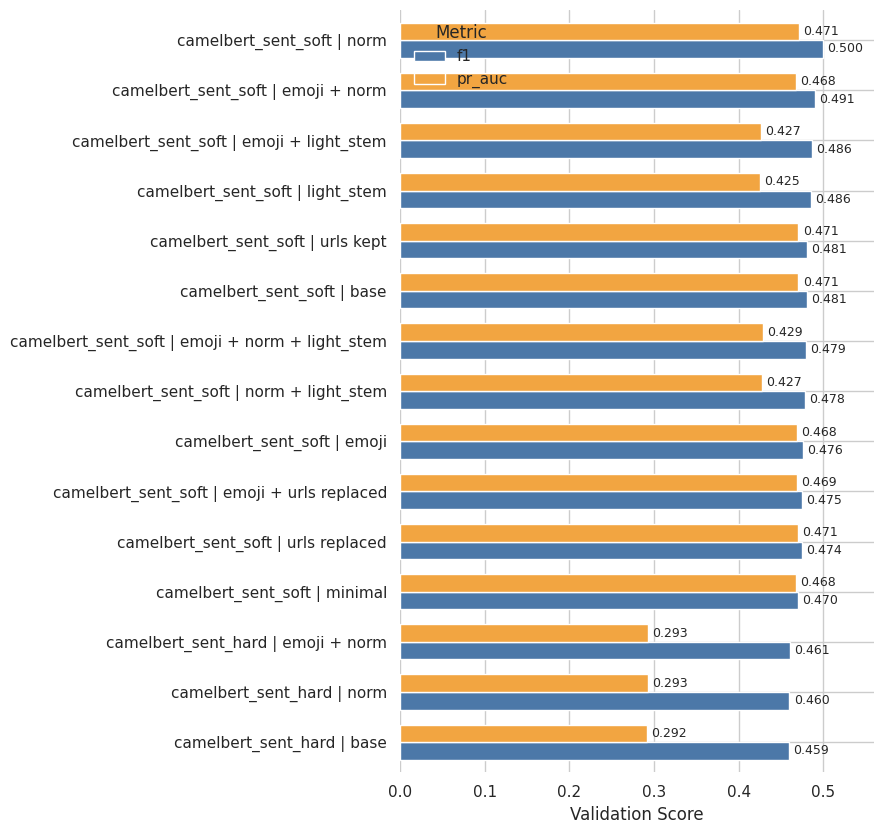

In [12]:
summary = table.assign(name=table["model"] + " | " + table["preprocessing"]).set_index("name")
plot_results(summary.nlargest(15, "f1"))